In [1]:
# 1. Загрузите изображение в оттенках серого sar_1_gray.jpg. 
# 2. постройте гистограмму
# 3. реализуйте алгоритм гамма коррекции с параметром гамма <1, >1.
# 4. Сравните исходное изображение, скорректированное при помощи гамма-фильтра. MSE, SSIM.
# 5. реализуйте алгоритм статистической цветокоррекции на основе статистики eq_gray.
# 6. Протестируйте работу алгоритмов пороговой фильтрации с различными параметрами.
# Для каждого решения - напечатайте результат


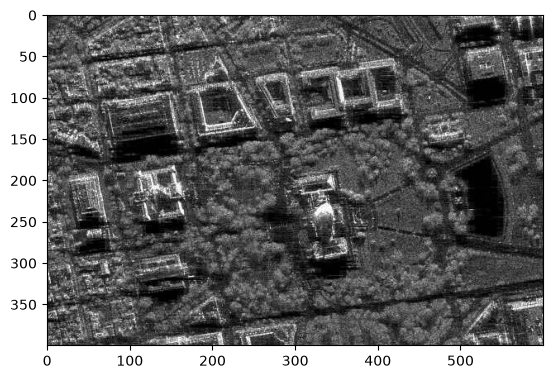

In [28]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

#1
image = cv2.imread('sar_1_gray.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')



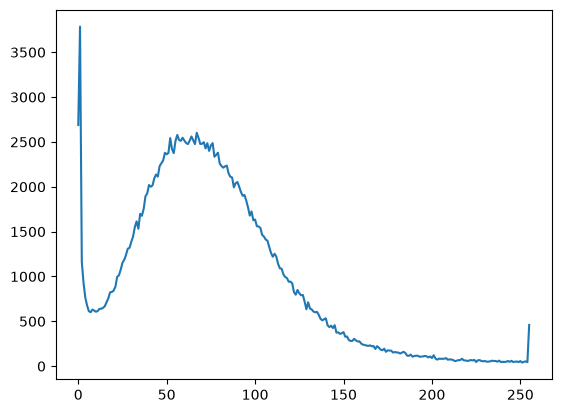

In [30]:
#2
histSize = 256
histRange = (0, 256)
accumulate = False

hist = cv2.calcHist([image_gray], [0], None, [histSize], histRange, accumulate=accumulate)
plt.plot(b_hist)

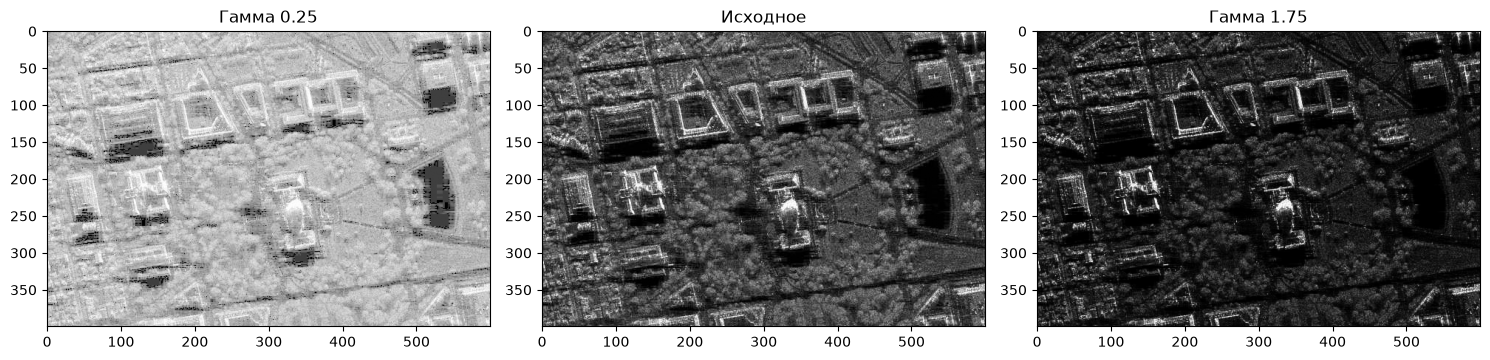

In [31]:
#3
def gamma_correction(image, gamma):
    normalized = image / 255.0
    corrected = np.power(normalized, gamma) * 255
    return corrected.astype(np.uint8)

gamma_025 = gamma_correction(image_gray, 0.25)
gamma_175 = gamma_correction(image_gray, 1.75)

plt.figure(figsize=(15, 10))

plt.subplot(1, 3, 1)
plt.imshow(gamma_025, cmap='gray')
plt.title('Гамма 0.25')

plt.subplot(1, 3, 2)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное')

plt.subplot(1, 3, 3)
plt.imshow(gamma_175, cmap='gray')
plt.title('Гамма 1.75')

plt.tight_layout()
plt.show()

In [33]:
#4
from skimage.metrics import structural_similarity, mean_squared_error

mse_gamma_025 = mean_squared_error(image_gray, gamma_025)
ssim_gamma_025 = structural_similarity(image_gray, gamma_025)

mse_gamma_175 = mean_squared_error(image_gray, gamma_175)
ssim_gamma_175 = structural_similarity(image_gray, gamma_175)

print(f'Гамма 0.25:\nMSE:{mse_gamma_025:.2f}  SSIM:{ssim_gamma_025:.4f}')
print()
print(f'Гамма 1.75:\nMSE:{mse_gamma_175:.2f}  SSIM:{ssim_gamma_175:.4f}')

Гамма 0.25:
MSE:11215.65  SSIM:0.5676

Гамма 1.75:
MSE:1693.90  SSIM:0.6601


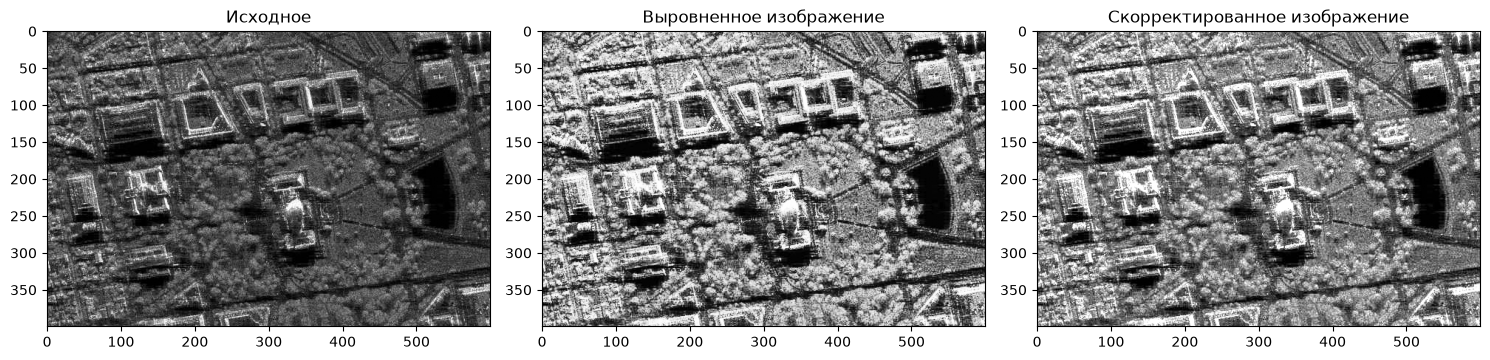

In [35]:
#5
mean = image_gray.mean()
std = image_gray.std()

eq_gray = cv2.equalizeHist(image_gray)

eq_mean = eq_gray.mean()
eq_std = eq_gray.std()

stat_corrected = (image_gray.astype(float) - mean) * (eq_std / std) + eq_mean
stat_corrected = np.clip(stat_corrected, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 10))

plt.subplot(1, 3, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное')

plt.subplot(1, 3, 2)
plt.imshow(eq_gray, cmap='gray')
plt.title('Выровненное изображение')

plt.subplot(1, 3, 3)
plt.imshow(stat_corrected, cmap='gray')
plt.title('Скорректированное изображение')

plt.tight_layout()
plt.show()

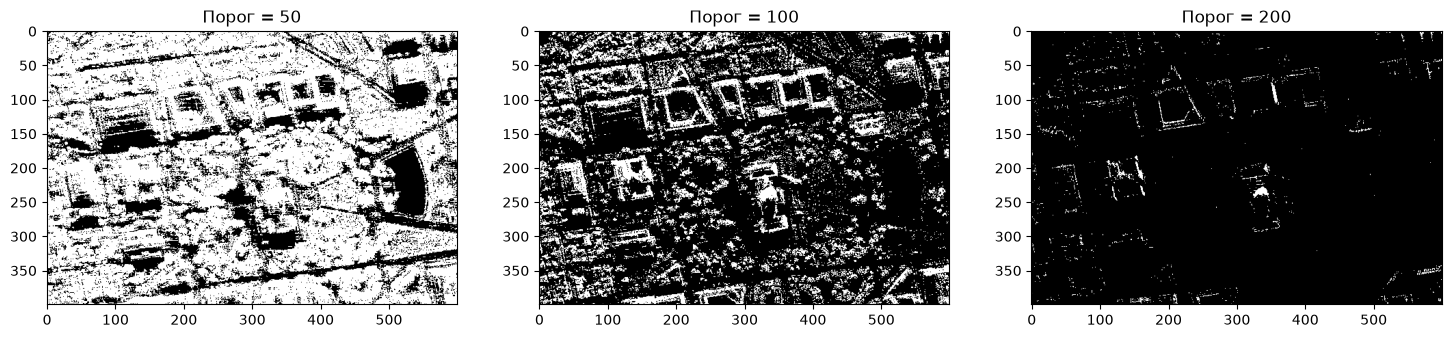

In [39]:
#6
thresh_values = [50, 100, 200]

plt.figure(figsize=(18, 14))

for i, thresh in enumerate(thresh_values):
    _, img_thresh = cv2.threshold(image, thresh, 255, cv2.THRESH_BINARY)
    plt.subplot(1, 3, 1 + i)
    plt.imshow(img_thresh, cmap='gray')
    plt.title(f'Порог = {thresh}')

plt.show()